In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils
from models import model_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(analysis_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
file_id = 2
organism = 'mouse'
model_variant = 'ns'

neuron_labels = ['02_8146', '02_2174', '02_7204', '02_233', '02_7412', '02_2214', '02_8097', '02_7331', '02_1408', '02_1246']

In [4]:
filename, traces, behavior, classes, (continuous_behaviors, motion_masks, motion_pcs) = analysis_utils.read_data(organism, file_id)
neuron_labels = [label for label in neuron_labels if label in traces.columns]

In [5]:
bom_params, hgm_params = analysis_utils.read_models(read_utils.get_model_path(), filename, model_variant, manual=False)

((_, bom_man, bom_rec, bom_res, bom_pres, _, _),
 (_, hgm_man, hgm_rec, hgm_res, hgm_pres, _, _)) = analysis_utils.read_predictions(read_utils.get_model_path(), filename, model_variant, manual=False)

# manifold

In [10]:
pca_modes, _, _, pca_vars_expl = train_utils.get_manifolds_pca([traces], scale=False, n_pc=hgm_man[0].values.shape[1])

In [6]:
bom_manifolds, bom_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)
hgm_manifolds, hgm_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)

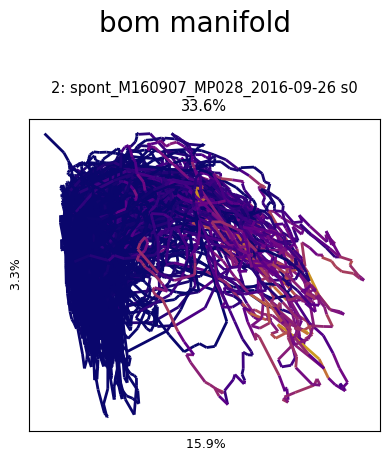

33.6%


In [7]:
plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(len(bom_manifolds))],
						  [bom_manifolds[s] for s in range(len(bom_manifolds))],
						  [continuous_behaviors[['running_speed']] for _ in range(len(bom_manifolds))],
						  bom_manifold_vars_expl, None,
						  title='bom manifold', plots_per_row=len(bom_manifolds), top_space=0.5,
						  save_path=None)

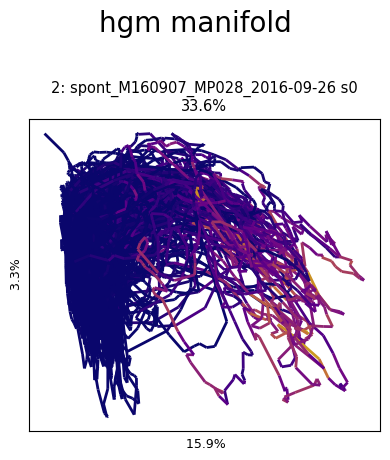

33.6%


In [8]:
plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(len(hgm_manifolds))],
						  [hgm_manifolds[s] for s in range(len(hgm_manifolds))],
						  [continuous_behaviors[['running_speed']] for _ in range(len(bom_manifolds))],
						  hgm_manifold_vars_expl, None,
						  title='hgm manifold', plots_per_row=len(hgm_manifolds), top_space=0.5,
						  save_path=None)

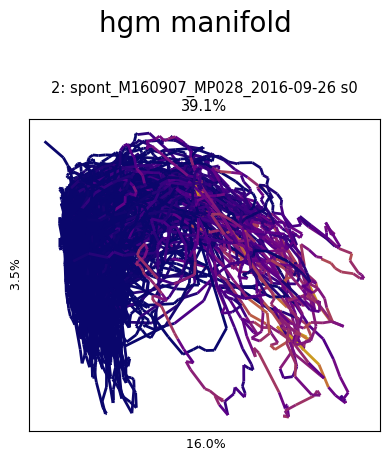

39.1%


In [11]:
plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(len(hgm_manifolds))],
						  [pca_modes[s] for s in range(len(hgm_manifolds))],
						  [continuous_behaviors[['running_speed']] for _ in range(len(bom_manifolds))],
						  pca_vars_expl, None,
						  title='hgm manifold', plots_per_row=len(hgm_manifolds), top_space=0.5,
						  save_path=None)

# MANIFOLD COLORING

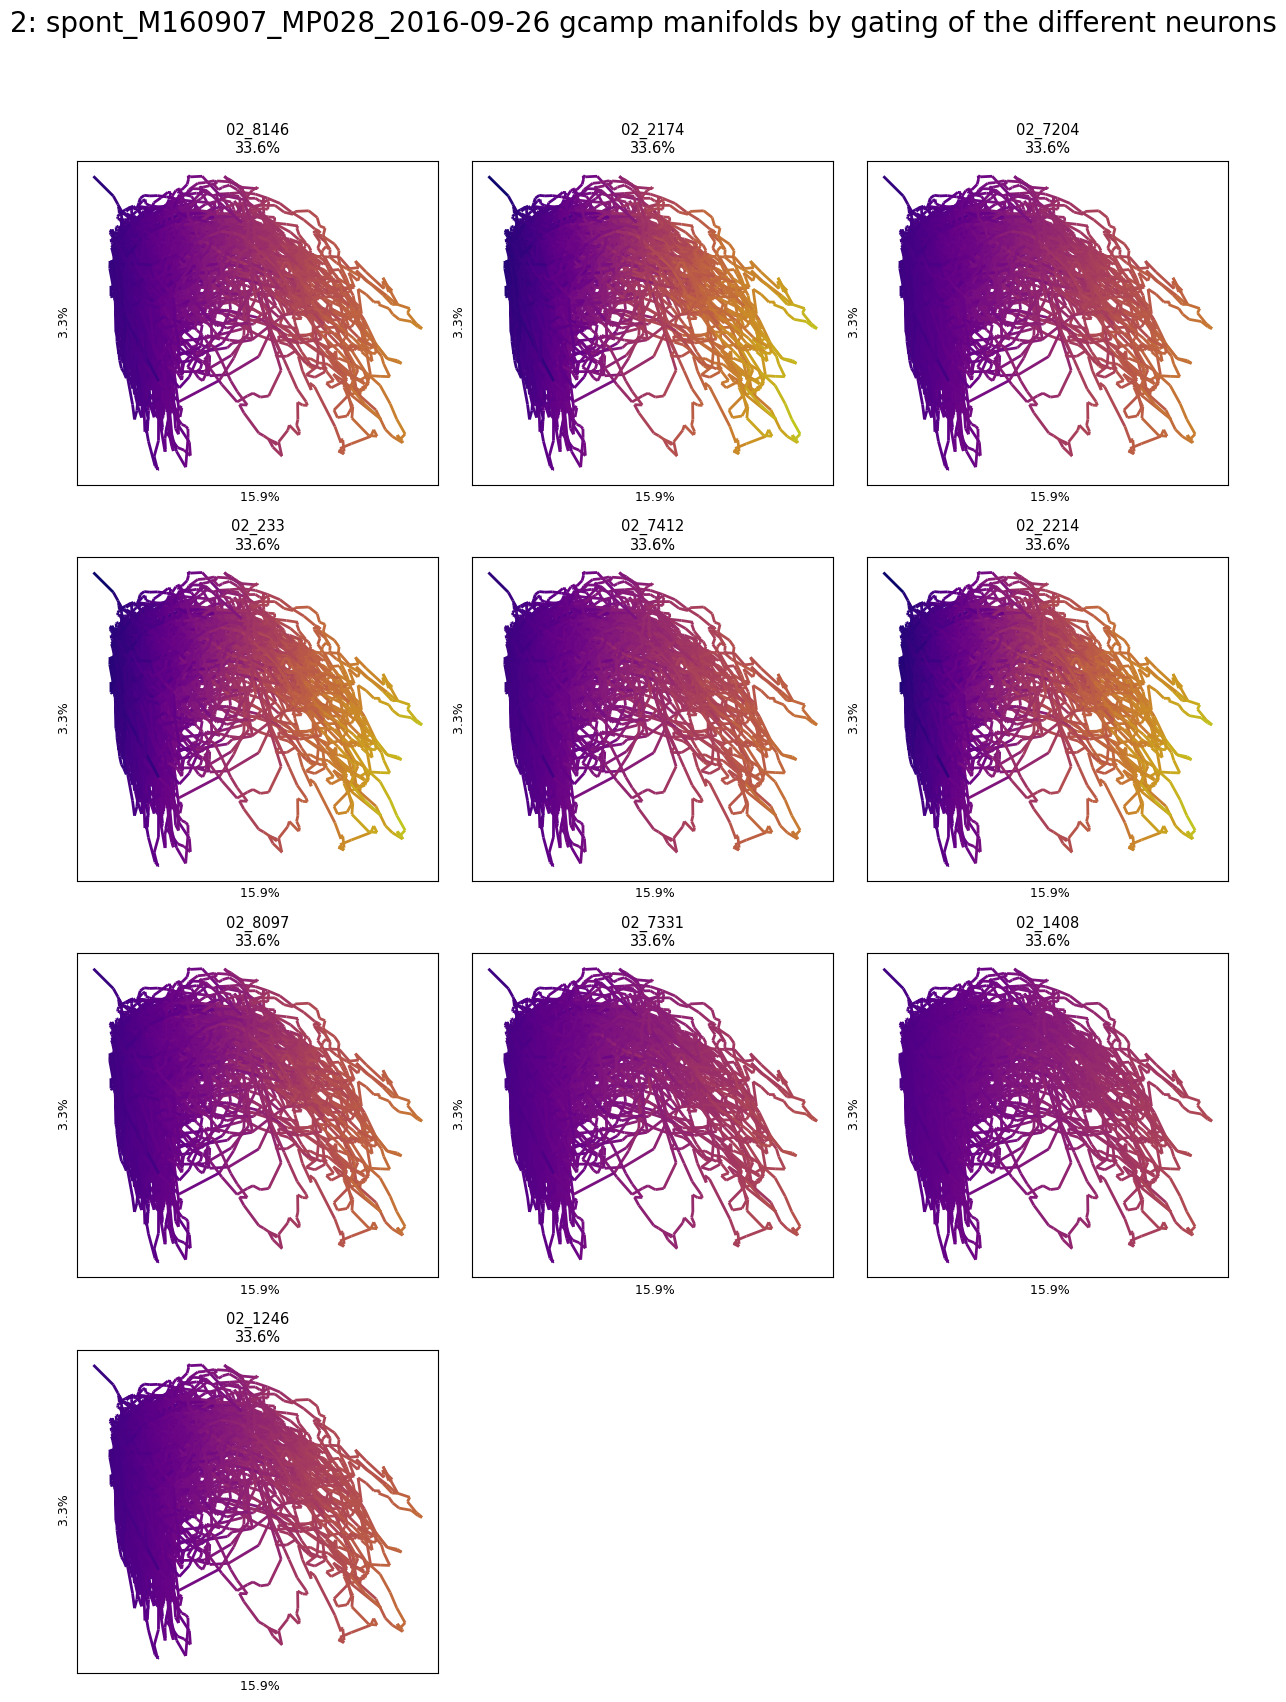

33.6%


In [11]:
sigmoid = lambda x: 1 / (1 + np.exp(-x))

neuron_ids = [traces.columns.get_loc(neuron) for neuron in neuron_labels]

sigmoid_terms = list()
manifold_terms = list()
vars_explained = list()

for neuron_id in neuron_ids:
	hgm_man_zs = (hgm_man[0].values - hgm_man[0].values.mean(axis=0)) / np.where((N_std := hgm_man[0].values.std(axis=0)) == 0.0, 1.0, N_std)
	WM = hgm_params[0]['model']['WM'][:, neuron_ids]
	sigmoid_term = sigmoid(hgm_man_zs @ WM)
	sigmoid_terms.append(pd.DataFrame(data=sigmoid_term))

	decode = lambda X: X @ model_utils.orthonormalize_qr(hgm_params[0]['model']['UN']).T
	manifold_term, var_explained = train_utils.postprocess_manifold(hgm_man[0].values, traces.values, decode, scale=False, align=True)
	manifold_terms.append(pd.DataFrame(data=manifold_term, columns=hgm_man[0].columns))
	vars_explained.append(var_explained)

plot_utils.plot_manifolds_gradient([f'{label}' for label in neuron_labels],
								   [manifold_terms[0]] * len(neuron_ids),
								   [sigmoid_terms[0].loc[:, i] for i in range(len(neuron_ids))],
								   vars_explained * len(neuron_ids), None,
								   title=f'{str(file_id)}: {filename} gcamp manifolds by gating of the different neurons',
								   plots_per_row=3, top_space=1,
								   save_path=None)

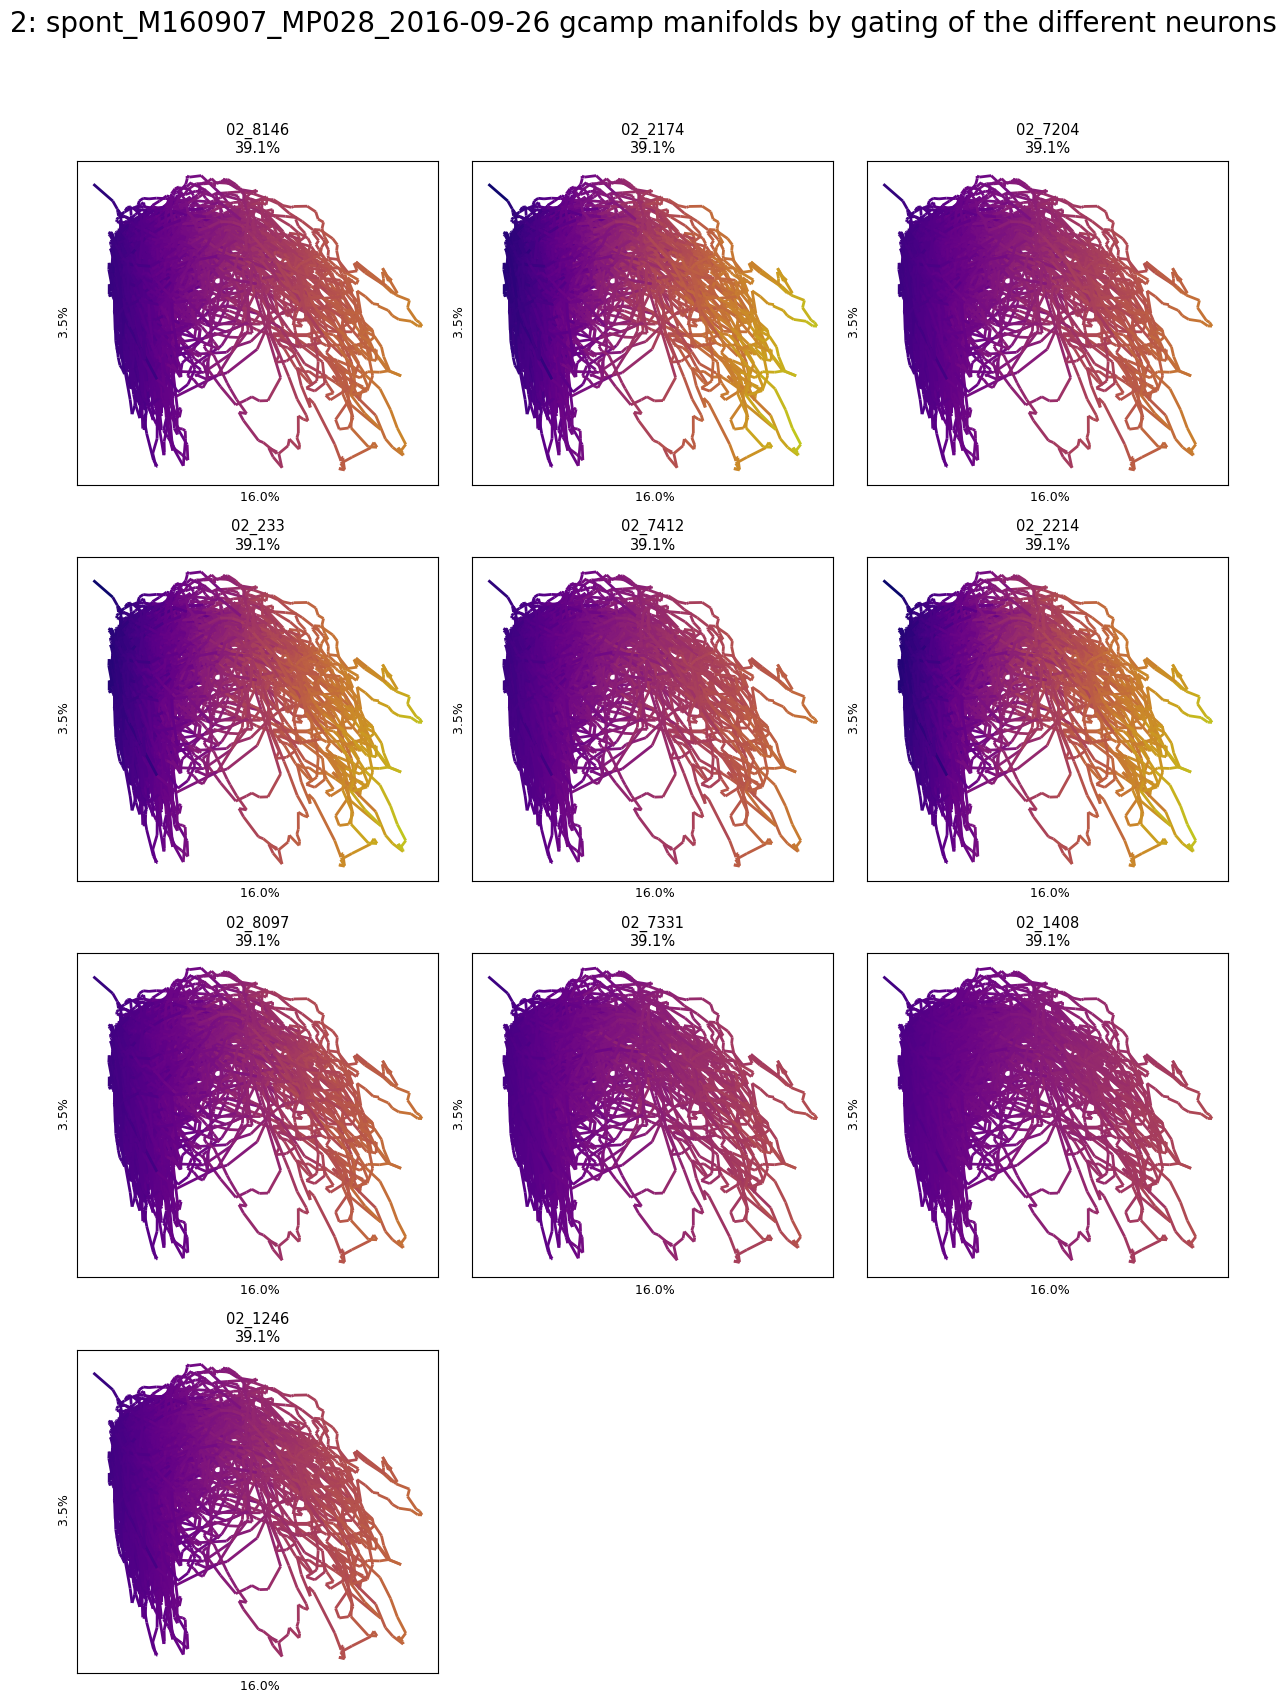

39.1%


In [12]:
sigmoid = lambda x: 1 / (1 + np.exp(-x))

neuron_ids = [traces.columns.get_loc(neuron) for neuron in neuron_labels]

plot_utils.plot_manifolds_gradient([f'{label}' for label in neuron_labels],
								   [pca_modes[0]] * len(neuron_ids),
								   [sigmoid_terms[0].loc[:, i] for i in range(len(neuron_ids))],
								   pca_vars_expl * len(neuron_ids), None,
								   title=f'{str(file_id)}: {filename} gcamp manifolds by gating of the different neurons',
								   plots_per_row=3, top_space=1,
								   save_path=None)

# traces

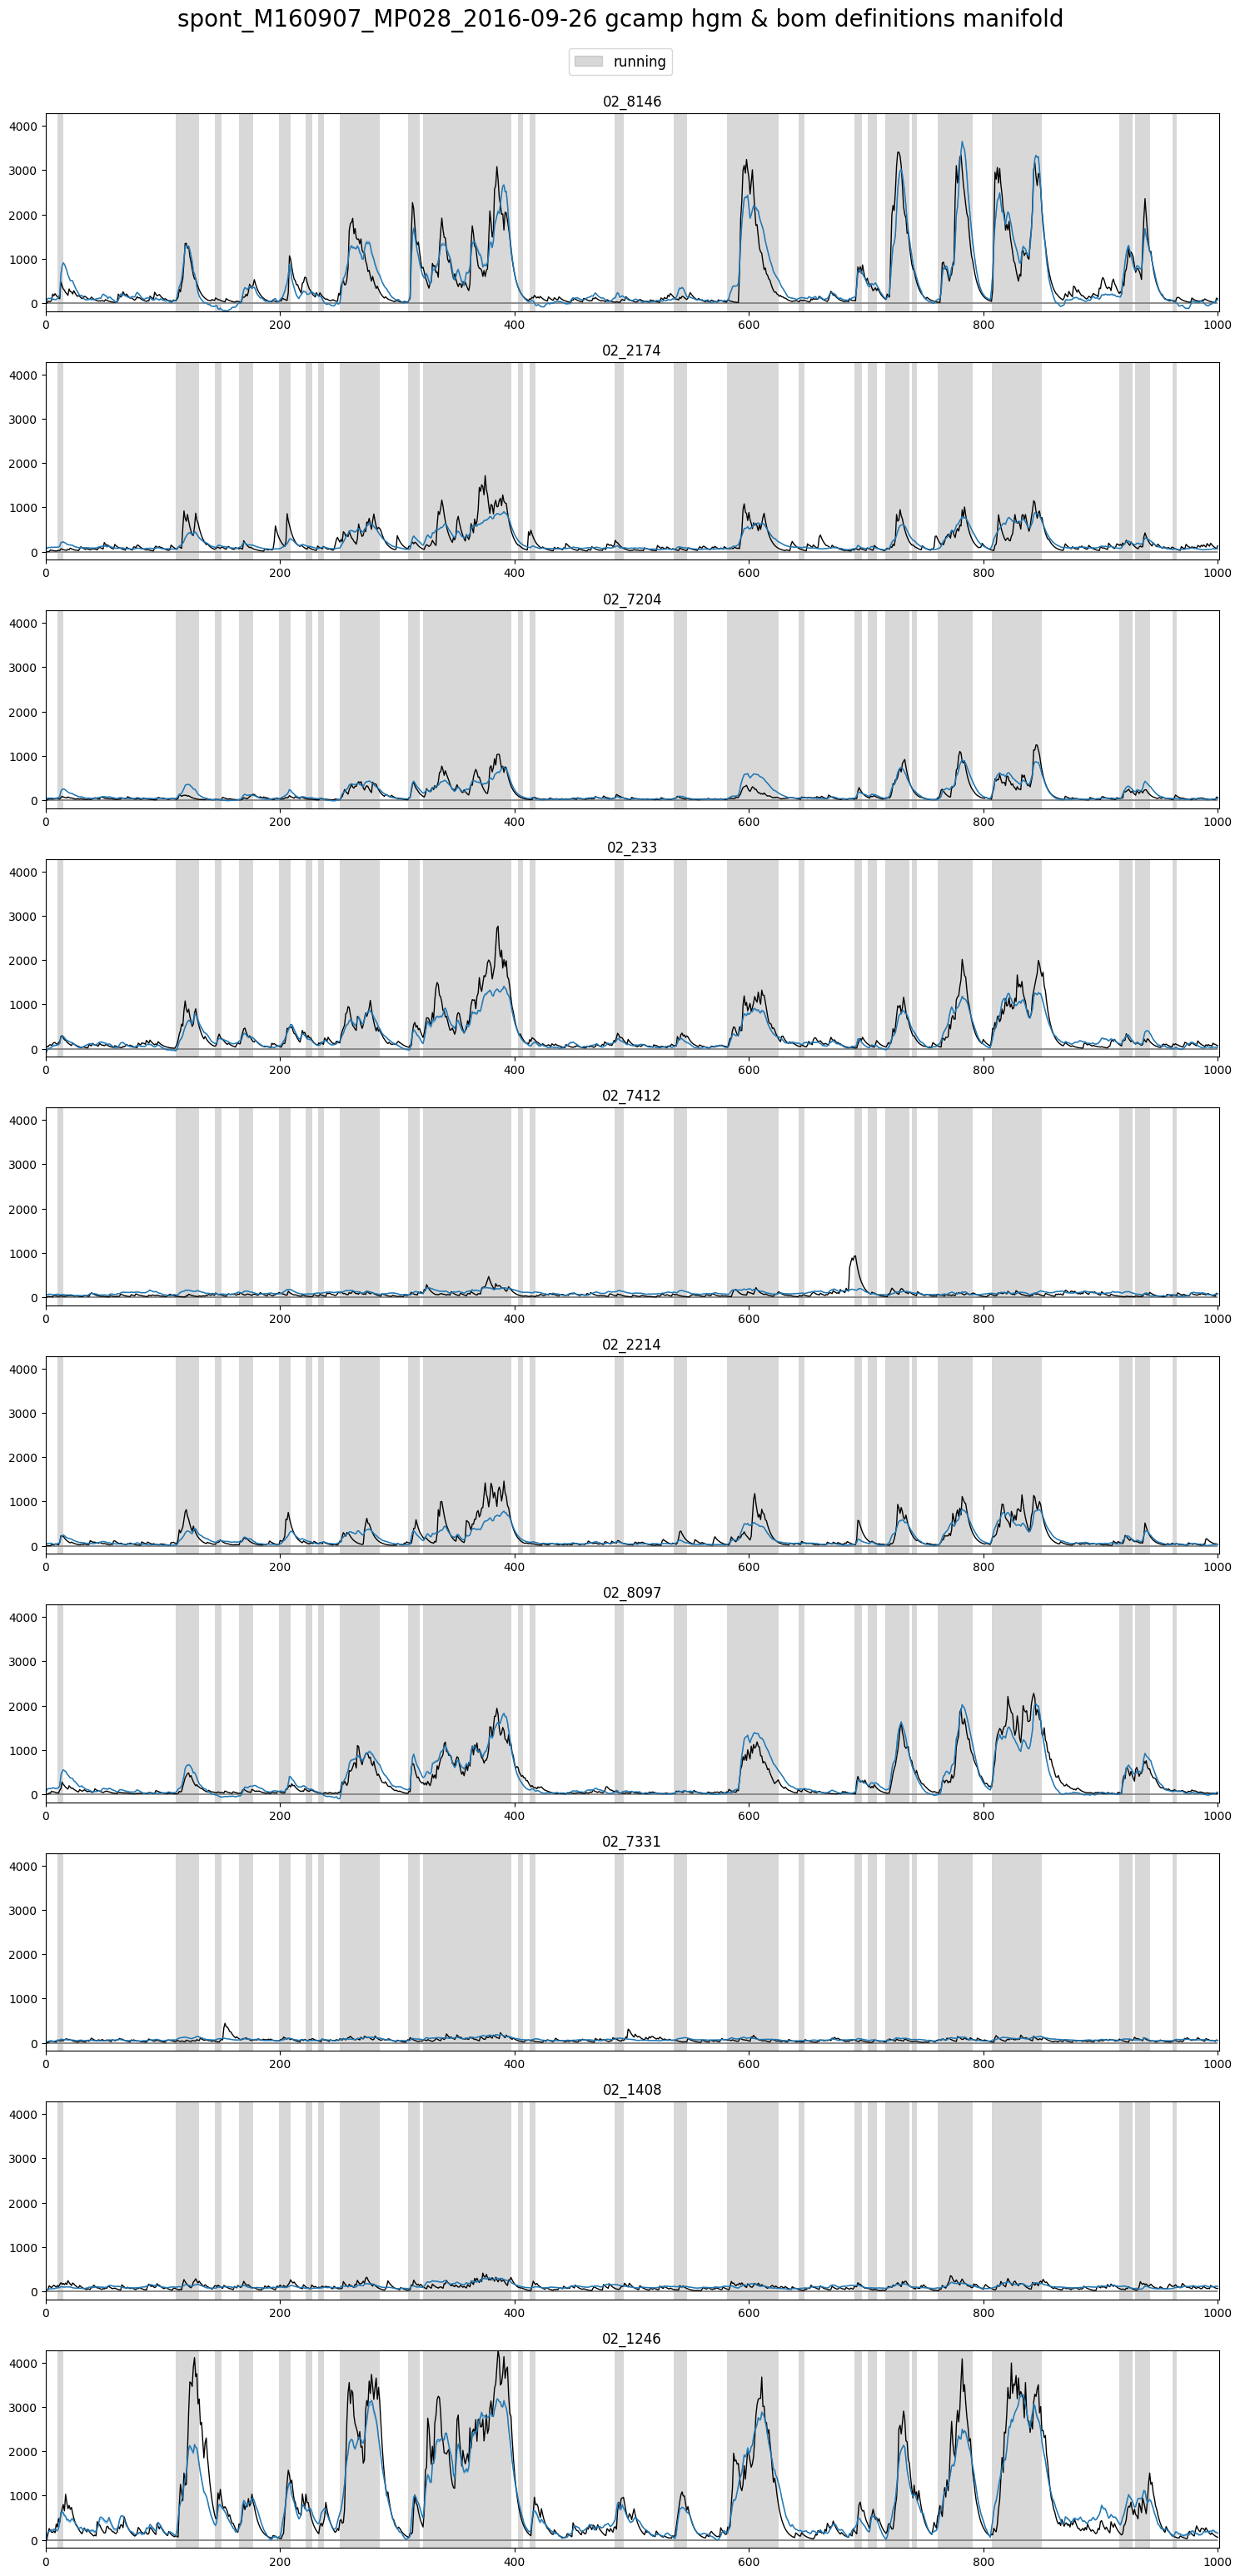

In [12]:
max_x = 1000
# max_x = traces.values.shape[0]

plot_utils.plot_traces_splits(
	[hgm_rec[i].loc[:max_x, neuron_labels] for i in range(len(hgm_rec))],
	[bom_rec[i].loc[:max_x, neuron_labels] for i in range(len(hgm_rec))],
	traces.loc[:max_x, neuron_labels],
	classes.loc[:max_x, ['run']], label='running',
	title=f'{filename} gcamp hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_MAN'

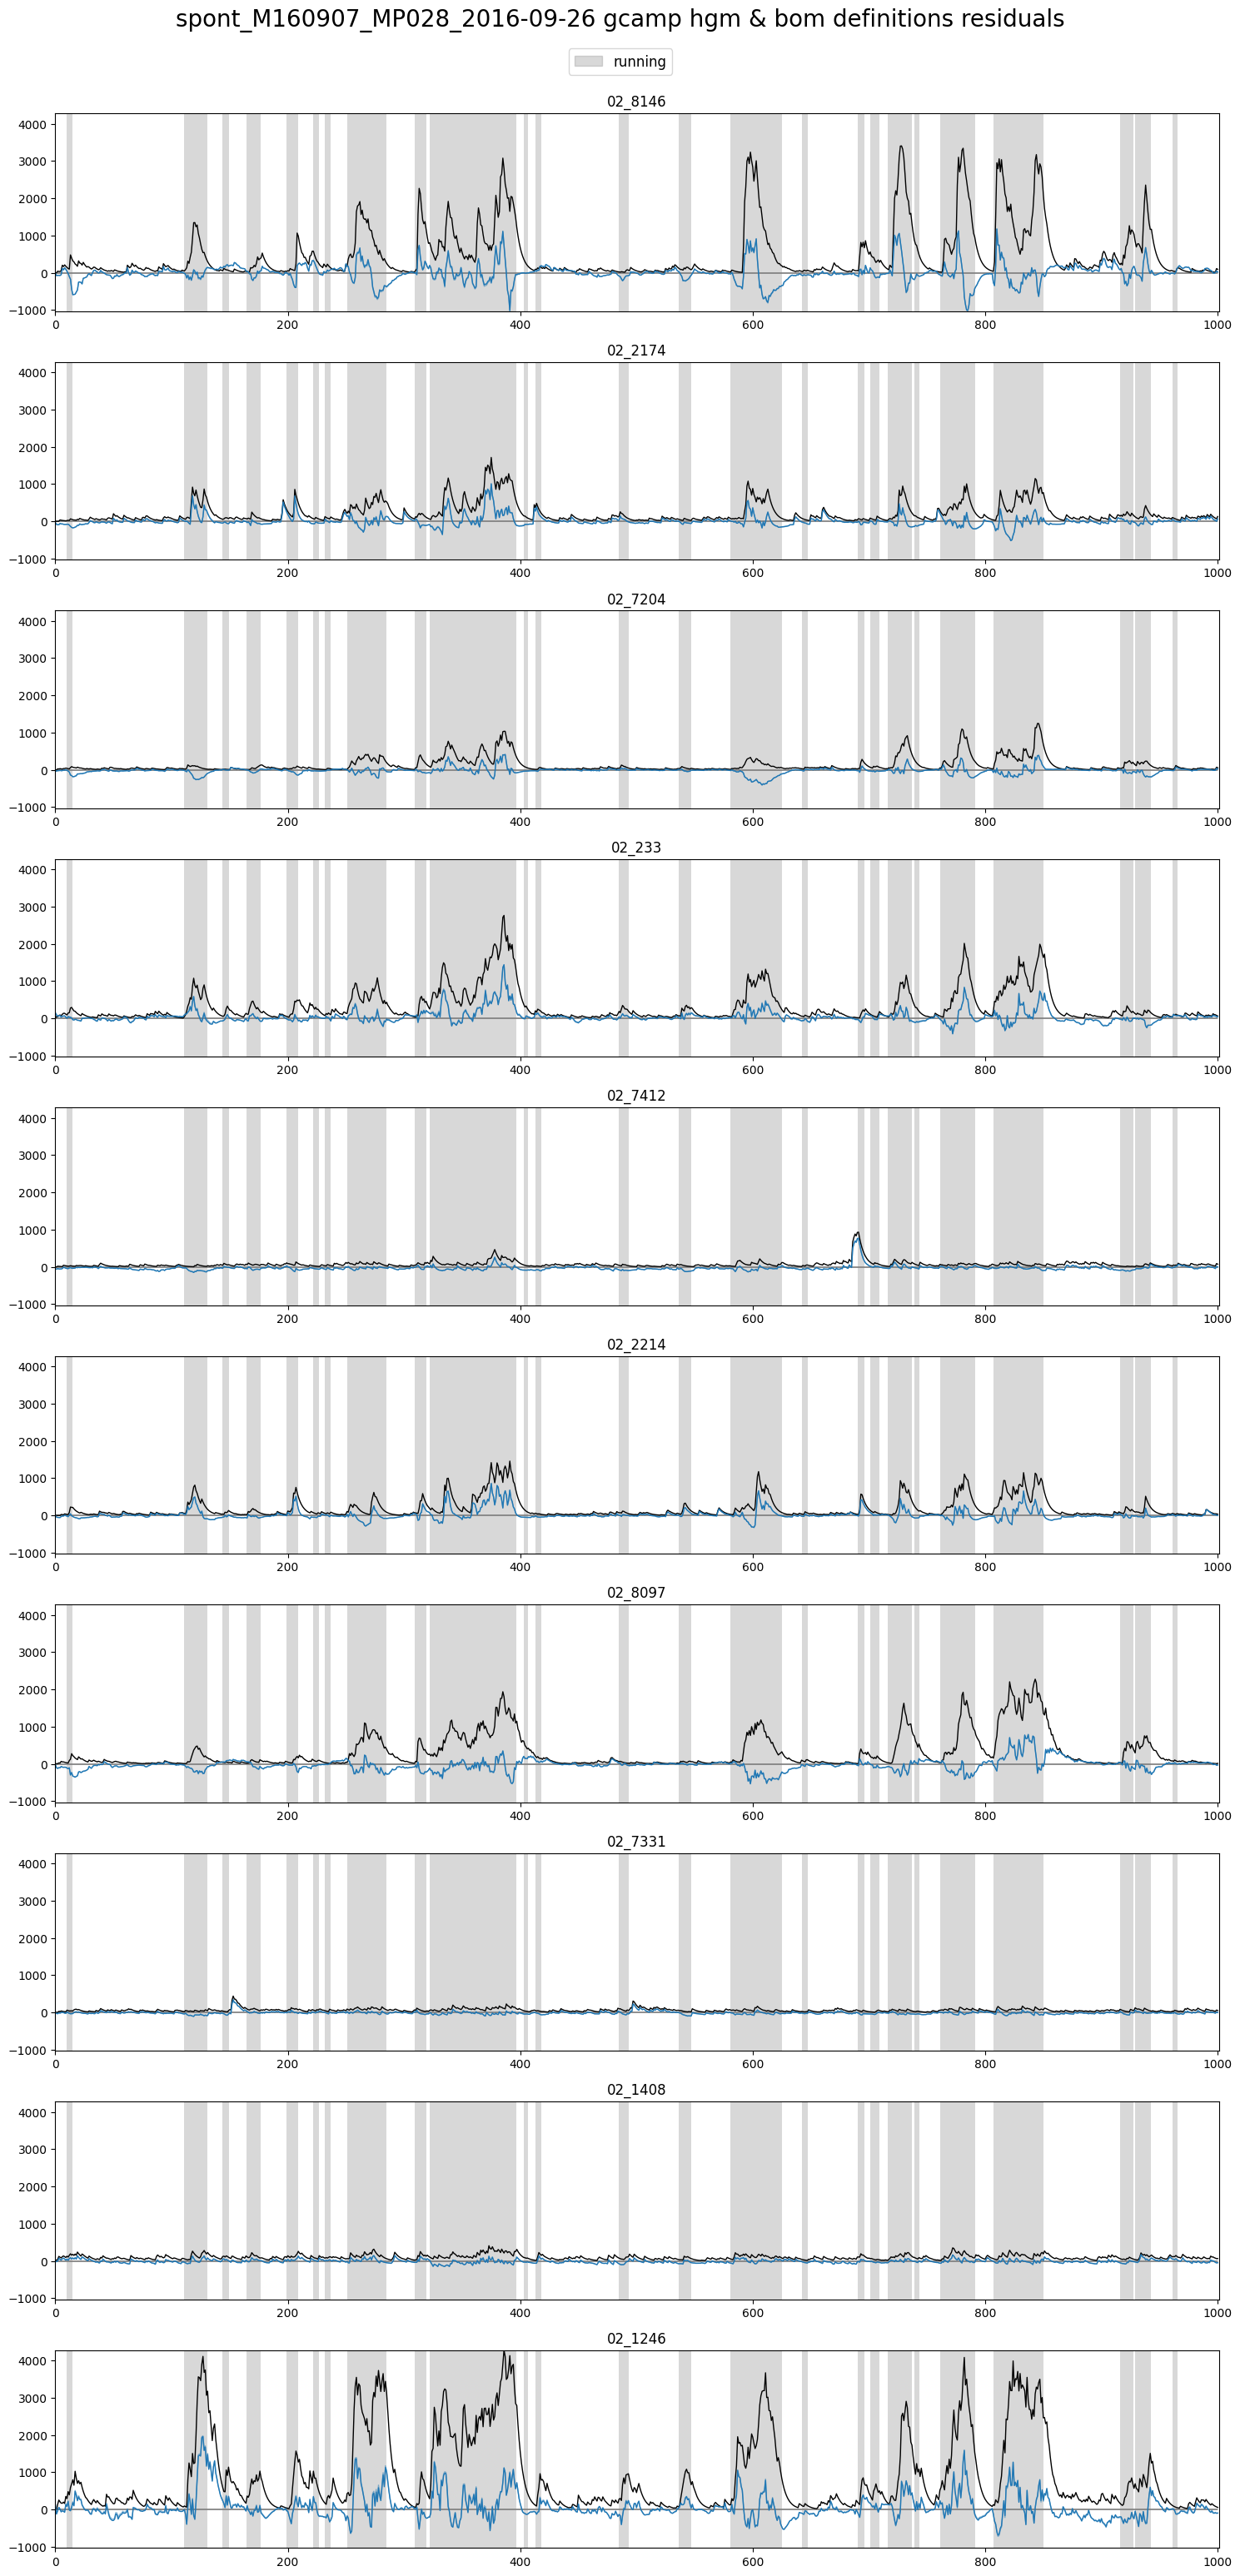

In [19]:
max_x = 1000
# max_x = traces.values.shape[0]

plot_utils.plot_traces_splits(
	[hgm_res[0].loc[:max_x, neuron_labels]],
	[bom_res[0].loc[:max_x, neuron_labels]],
	traces.loc[:max_x, neuron_labels],
	classes.loc[:max_x, ['run']], label='running',
	title=f'{filename} gcamp hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_RES'

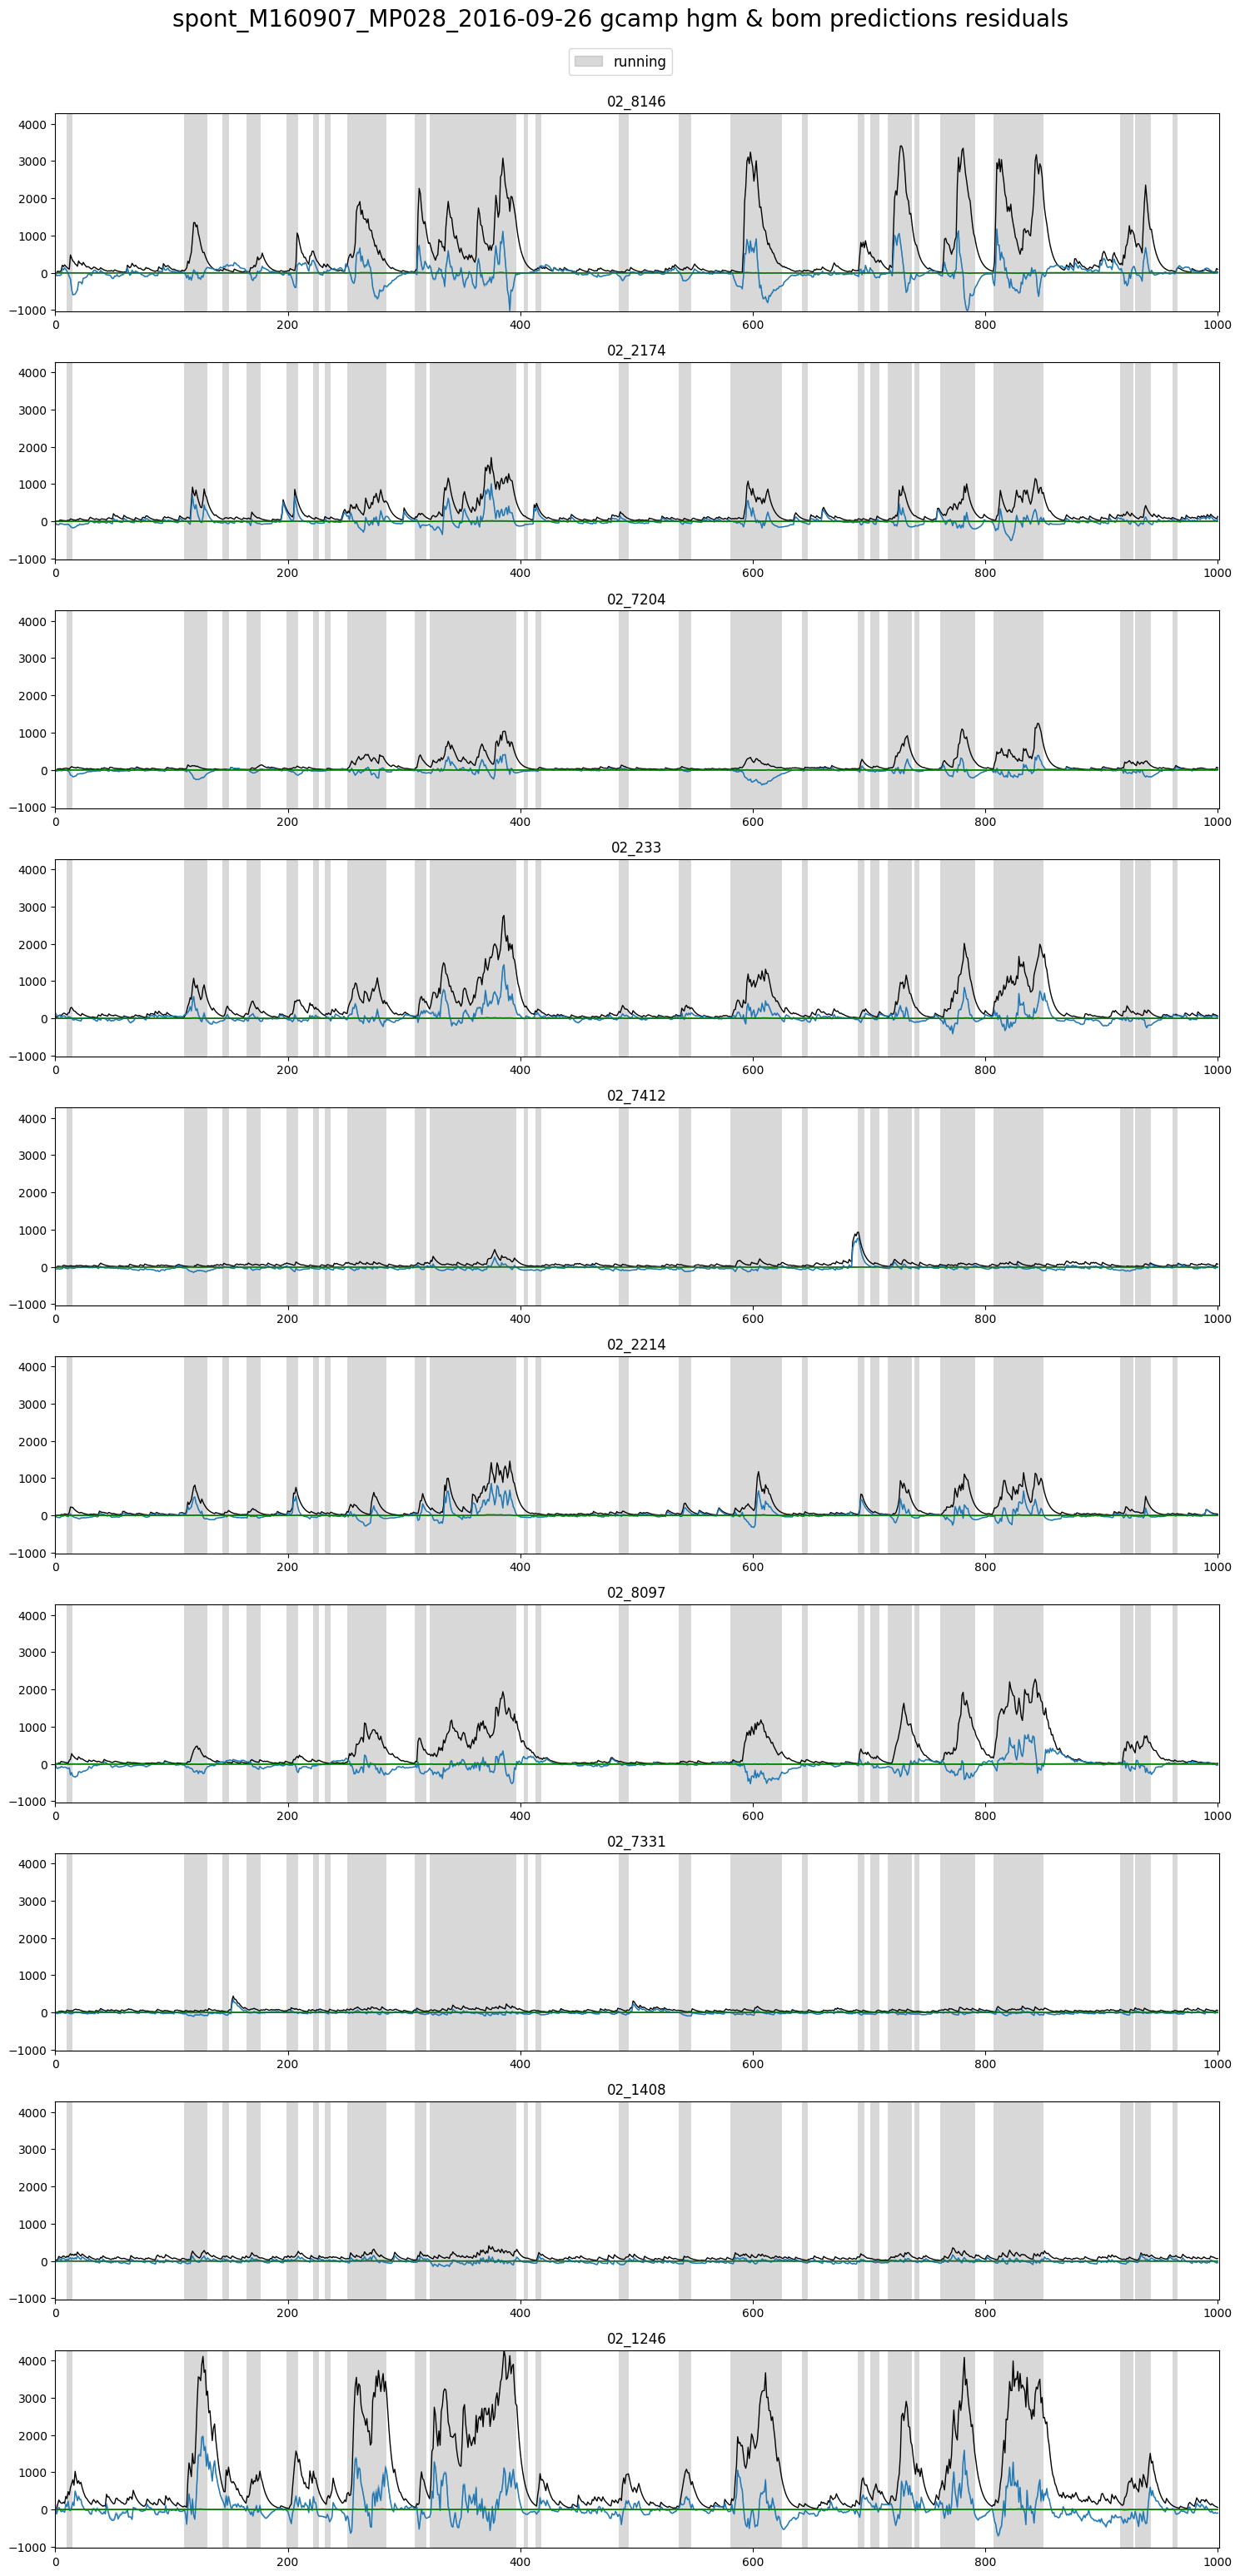

In [20]:
max_x = 1000
# max_x = traces.values.shape[0]

plot_utils.plot_traces_splits_pairs(
	[hgm_res[0].loc[:max_x, neuron_labels],
	 hgm_pres[0].loc[:max_x, neuron_labels]],
	[bom_res[0].loc[:max_x, neuron_labels],
	 bom_pres[0].loc[:max_x, neuron_labels]],
	traces.loc[:max_x, neuron_labels],
	classes.loc[:max_x, ['run']], label='running',
	title=f'{filename} gcamp hgm & bom predictions residuals', ylimits=None, plots_per_row=1,
	save_path=None)  #../../out/plots/f'GCAMP_PRES_S{i}'